# DSCI 552 Homework 7
Name: Hongwei Xiao  
GitHub username: Ga9a

## 1. Multi-class and multi-label classification
### (a) Data and train/test split
I used the 22 MFCC features to predict Family, Genus, and Species. RecordID is an identifier, so I left it out. The split is 70% training and 30% test, stratified by Species with seed 42.

In [1]:
from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import accuracy_score, recall_score, calinski_harabasz_score
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from joblib import Parallel, delayed, parallel_config
from threadpoolctl import threadpool_limits

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)
SEED = 42
TARGETS = ['Family', 'Genus', 'Species']
data = pd.read_csv(ROOT / 'data/Frogs_MFCCs.csv')
features = [c for c in data if c.startswith('MFCCs_')]
X = data[features].to_numpy()
Y = data[TARGETS].to_numpy()
assert X.shape == (7195, 22) and not data.isna().any().any()
train_idx, test_idx = train_test_split(
    np.arange(len(data)), test_size=0.3, random_state=SEED,
    stratify=data['Species'])
X_train, X_test = X[train_idx], X[test_idx]
Y_train, Y_test = Y[train_idx], Y[test_idx]
pd.DataFrame({'row': np.r_[train_idx, test_idx],
              'split': ['train'] * len(train_idx) + ['test'] * len(test_idx)}
             ).to_csv(RESULTS / 'split.csv', index=False)
print(f'Rows: {len(data)}, features: {len(features)}')
print(f'Train: {len(train_idx)}, test: {len(test_idx)}, missing: 0')
display(pd.DataFrame({c: [data[c].nunique()] for c in TARGETS},
                     index=['Number of classes']))
display(data['Species'].value_counts().rename('Count').to_frame())

Rows: 7195, features: 22
Train: 5036, test: 2159, missing: 0


,Family,Genus,Species
Number of classes,4,8,10


,Count
Species,
AdenomeraHylaedactylus,3478
HypsiboasCordobae,1121
AdenomeraAndre,672
Ameeregatrivittata,542
HypsiboasCinerascens,472
HylaMinuta,310
LeptodactylusFuscus,270
ScinaxRuber,148
OsteocephalusOophagus,114


### (b)(i) Evaluation
For row $i$, let $d_i$ be the number of wrong labels out of the three targets.

- Exact match: $\frac{1}{n}\sum_i I(d_i=0)$. All three labels must be correct.
- Mean Hamming distance: $\frac{1}{n}\sum_i d_i$.
- Hamming loss: $\frac{1}{3n}\sum_i d_i$.
- Hamming score (label accuracy): $1-\text{Hamming loss}$.

Some references use “Hamming score” for the set-based Jaccard score. I also report that separately: if $m_i=3-d_i$, the intersection has $m_i$ labels and the union has $6-m_i$. Labels are distinguished by target, so a Family name is not matched against a Genus name.

In [2]:
def evaluate_labels(y_true, y_pred):
    correct = np.asarray(y_true) == np.asarray(y_pred)
    matches = correct.sum(axis=1)
    return {
        'Exact match': np.mean(matches == 3),
        'Hamming distance': np.mean(3 - matches),
        'Hamming score': correct.mean(),
        'Hamming loss': 1 - correct.mean(),
        'Jaccard score': np.mean(matches / (6 - matches))
    }

scores, details, predictions = [], [], {}
def fit_svm(name, estimator, grid):
    pred = np.empty(Y_test.shape, dtype=object)
    rows = []
    for j, target in enumerate(TARGETS):
        start = time.perf_counter()
        pipe = Pipeline([('scale', StandardScaler()),
                         ('ovr', OneVsRestClassifier(estimator, n_jobs=1))])
        cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
        search = GridSearchCV(pipe, grid, scoring='accuracy', cv=cv,
                              n_jobs=6, error_score='raise', refit=True)
        with threadpool_limits(limits=1), parallel_config(backend='threading'):
            search.fit(X_train, Y_train[:, j])
        pred[:, j] = search.predict(X_test)
        pd.DataFrame(search.cv_results_).to_csv(
            RESULTS / f'{name}_{target}_cv.csv', index=False)
        params = {key.split('__')[-1]: value
                  for key, value in search.best_params_.items()}
        rows.append({'Model': name, 'Target': target, **params,
                     'CV accuracy': search.best_score_,
                     'Test accuracy': accuracy_score(Y_test[:, j], pred[:, j]),
                     'Test macro recall': recall_score(Y_test[:, j], pred[:, j],
                                                       average='macro')})
        print(f'{name}, {target}: {params}; {time.perf_counter()-start:.1f}s')
    details.extend(rows)
    predictions[name] = pred
    scores.append({'Model': name, **evaluate_labels(Y_test, pred)})
    saved = pd.DataFrame({'row': test_idx})
    for j, target in enumerate(TARGETS):
        saved[target + '_true'] = Y_test[:, j]
        saved[target + '_pred'] = pred[:, j]
    saved.to_csv(RESULTS / f'{name}_predictions.csv', index=False)
    display(pd.DataFrame(rows).round(5))
    display(pd.DataFrame([scores[-1]]).set_index('Model').round(5))

### (b)(ii) Gaussian SVM
I fit one classifier for each target, with one-versus-rest classifiers for its classes. Scaling is fitted inside each training fold. I searched $C\in\{0.1,1,10,100,1000\}$ and $\gamma\in\{0.001,0.01,0.1,1\}$ using 10-fold cross-validation. The Gaussian kernel is $\exp(-\gamma\|x-x'\|^2)$, so its width is $\sigma=1/\sqrt{2\gamma}$. The same split is used for all three methods.

In [3]:
fit_svm('RBF', SVC(kernel='rbf', cache_size=128), {
    'ovr__estimator__C': [0.1, 1, 10, 100, 1000],
    'ovr__estimator__gamma': [0.001, 0.01, 0.1, 1]
})

RBF, Family: {'C': 100, 'gamma': 0.01}; 35.4s


RBF, Genus: {'C': 10, 'gamma': 0.1}; 58.3s


RBF, Species: {'C': 1000, 'gamma': 0.01}; 71.1s


,Model,Target,C,gamma,CV accuracy,Test accuracy,Test macro recall
0,RBF,Family,100,0.01,0.98987,0.99259,0.98310
1,RBF,Genus,10,0.10,0.98848,0.99074,0.96577
2,RBF,Species,1000,0.01,0.98709,0.98981,0.96884


,Exact match,Hamming distance,Hamming score,Hamming loss,Jaccard score
Model,,,,,
RBF,0.98518,0.02686,0.99105,0.00895,0.98935


### (b)(iii) L1-penalized linear SVM
I standardized the features and used an L1 penalty with squared hinge loss. I chose C separately for each target with 10-fold cross-validation. The scaler again uses only the training fold.

In [4]:
linear_grid = {'ovr__estimator__C': [0.001, 0.01, 0.1, 1, 10, 100]}
fit_svm('L1', LinearSVC(penalty='l1', dual=False, max_iter=50000,
                        random_state=SEED), linear_grid)

L1, Family: {'C': 1}; 6.3s


L1, Genus: {'C': 100}; 14.0s


L1, Species: {'C': 100}; 15.7s


,Model,Target,C,CV accuracy,Test accuracy,Test macro recall
0,L1,Family,1,0.93427,0.93932,0.69920
1,L1,Genus,100,0.95334,0.94905,0.80191
2,L1,Species,100,0.95731,0.95970,0.88659


,Exact match,Hamming distance,Hamming score,Hamming loss,Jaccard score
Model,,,,,
L1,0.91709,0.15192,0.94936,0.05064,0.94011


### (b)(iv) Class imbalance
I used class weights as the imbalance remedy. In each one-versus-rest fit, `class_weight='balanced'` gives the smaller group more weight, using only that training fold. This avoids creating synthetic label combinations. I retuned C using the same 10-fold procedure.

In [5]:
fit_svm('L1_balanced', LinearSVC(penalty='l1', dual=False,
    class_weight='balanced', max_iter=50000, random_state=SEED), linear_grid)
comparison = pd.DataFrame(scores).set_index('Model')
target_results = pd.DataFrame(details)
comparison.to_csv(RESULTS / 'svm_comparison.csv')
target_results.to_csv(RESULTS / 'svm_target_results.csv', index=False)
display(comparison.round(5))
display(target_results.pivot(index='Target', columns='Model',
                             values='Test macro recall').round(5))

L1_balanced, Family: {'C': 1}; 9.8s


L1_balanced, Genus: {'C': 10}; 21.9s


L1_balanced, Species: {'C': 1}; 24.4s


,Model,Target,C,CV accuracy,Test accuracy,Test macro recall
0,L1_balanced,Family,1,0.92692,0.92774,0.92378
1,L1_balanced,Genus,10,0.93368,0.93191,0.87269
2,L1_balanced,Species,1,0.94956,0.95090,0.88846


,Exact match,Hamming distance,Hamming score,Hamming loss,Jaccard score
Model,,,,,
L1_balanced,0.89208,0.18944,0.93685,0.06315,0.92385


,Exact match,Hamming distance,Hamming score,Hamming loss,Jaccard score
Model,,,,,
RBF,0.98518,0.02686,0.99105,0.00895,0.98935
L1,0.91709,0.15192,0.94936,0.05064,0.94011
L1_balanced,0.89208,0.18944,0.93685,0.06315,0.92385


Model,L1,L1_balanced,RBF
Target,,,
Family,0.69920,0.92378,0.98310
Genus,0.80191,0.87269,0.96577
Species,0.88659,0.88846,0.96884


RBF gave the best exact match on this split: 98.52%, compared with 91.71% for L1 and 89.21% for balanced L1. Its Hamming loss was 0.0090. The nonlinear boundary worked better for these features.

Class weighting changed the average macro recall across the three targets from 0.7959 to 0.8950, while Hamming loss changed from 0.0506 to 0.0631. Weighting improved macro recall, but reduced overall accuracy. I would use the RBF model here based on the overall test results. These results use a random row split; recordings can appear in both sets.

## 2. K-means Monte Carlo simulation
### (a) Choosing k
I repeated the whole procedure 50 times with seeds 42 through 91. Each run fits K-means on all 7,195 rows and searches k from 1 to 50. I use the original normalized MFCCs here. The Calinski-Harabasz (CH) score selects k; higher is better. CH is undefined for k=1, so I record its inertia as a baseline and choose among k=2,...,50. Every candidate uses 10 initializations. The true labels are not used to choose k.

### (b) Cluster labels
Within each selected cluster, I take the most common Family, Genus, and Species separately. Alphabetical order breaks a tie. The triplet is then assigned to every row in that cluster.

### (c) Hamming results
I use the same three-label metrics as above, then report their mean and sample standard deviation across 50 runs. These measure agreement on the clustered data, rather than prediction on a held-out test set.

In [6]:
def cluster_run(seed):
    with threadpool_limits(limits=1):
        curve, best_ch, best_labels, best_k = [], -np.inf, None, None
        for k in range(1, 51):
            km = KMeans(n_clusters=k, n_init=10, max_iter=300,
                        random_state=seed, algorithm='lloyd').fit(X)
            ch = calinski_harabasz_score(X, km.labels_) if k > 1 else np.nan
            curve.append({'seed': seed, 'k': k, 'CH': ch, 'inertia': km.inertia_})
            if k > 1 and ch > best_ch:
                best_ch, best_k, best_labels = ch, k, km.labels_.copy()
        predicted = np.empty(Y.shape, dtype=object)
        majority = []
        for cluster in range(best_k):
            mask = best_labels == cluster
            row = {'seed': seed, 'cluster': cluster, 'size': int(mask.sum())}
            for j, target in enumerate(TARGETS):
                labels, counts = np.unique(Y[mask, j], return_counts=True)
                label = labels[np.argmax(counts)]
                predicted[mask, j] = label
                row[target] = label
            majority.append(row)
        metrics = {'seed': seed, 'k': best_k, 'CH': best_ch,
                   **evaluate_labels(Y, predicted)}
        pd.DataFrame(curve).to_csv(RESULTS / f'kmeans_curve_{seed}.csv', index=False)
        pd.DataFrame(majority).to_csv(RESULTS / f'kmeans_majority_{seed}.csv', index=False)
        if seed == SEED:
            first = pd.DataFrame({'row': np.arange(len(X)), 'cluster': best_labels})
            for j, target in enumerate(TARGETS):
                first[target + '_true'] = Y[:, j]
                first[target + '_pred'] = predicted[:, j]
            first.to_csv(RESULTS / 'kmeans_first_run_predictions.csv', index=False)
        (RESULTS / f'kmeans_metrics_{seed}.json').write_text(json.dumps(metrics))
        return metrics

start = time.perf_counter()
with threadpool_limits(limits=1), parallel_config(backend='threading'):
    runs = Parallel(n_jobs=6)(delayed(cluster_run)(s) for s in range(42, 92))
runs = pd.DataFrame(runs)
runs.to_csv(RESULTS / 'kmeans_50_runs.csv', index=False)
metric_names = list(evaluate_labels(Y, Y))
summary = runs[metric_names].agg(['mean', 'std']).T
summary.to_csv(RESULTS / 'kmeans_summary.csv')
print(f'Finished {len(runs)} runs in {(time.perf_counter()-start)/60:.1f} minutes')
display(runs['k'].value_counts().sort_index().rename('Runs').to_frame())
display(summary.round(6))
display(pd.read_csv(RESULTS / 'kmeans_majority_42.csv'))

Finished 50 runs in 3.2 minutes


,Runs
k,
2,50


,mean,std
Exact match,0.636136,0.0
Hamming distance,0.895622,0.0
Hamming score,0.701459,0.0
Hamming loss,0.298541,0.0
Jaccard score,0.681890,0.0


,seed,cluster,size,Family,Genus,Species
0,42,0,3598,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,42,1,3597,Hylidae,Hypsiboas,HypsiboasCordobae


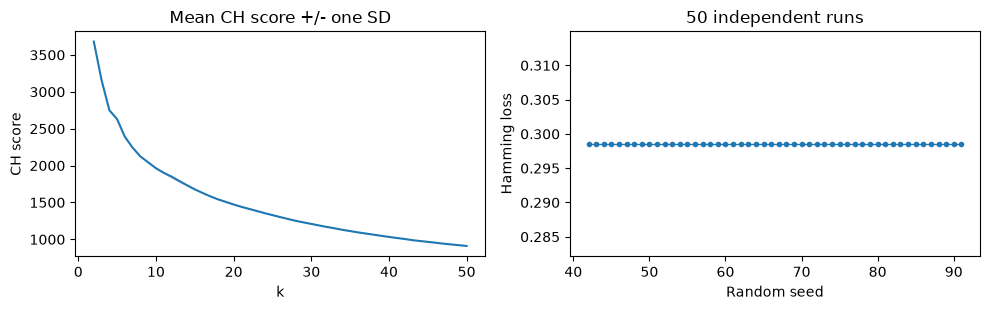

In [7]:
curves = pd.concat([pd.read_csv(RESULTS / f'kmeans_curve_{s}.csv')
                    for s in range(42, 92)], ignore_index=True)
curves.to_csv(RESULTS / 'kmeans_all_curves.csv', index=False)
ch_summary = curves.groupby('k')['CH'].agg(['mean', 'std'])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(ch_summary.index, ch_summary['mean'], lw=1.5)
axes[0].fill_between(ch_summary.index,
    ch_summary['mean'] - ch_summary['std'],
    ch_summary['mean'] + ch_summary['std'], alpha=0.2)
axes[0].set(xlabel='k', ylabel='CH score', title='Mean CH score +/- one SD')
axes[1].plot(runs['seed'], runs['Hamming loss'], marker='.', lw=1)
axes[1].set(xlabel='Random seed', ylabel='Hamming loss', title='50 independent runs')
fig.tight_layout()
fig.savefig(RESULTS / 'kmeans_results.png', dpi=160, bbox_inches='tight')
plt.show()

CH selected k=2 in 50 runs. The mean Hamming distance was 0.8956 (SD 0.0000). The mean Hamming score was 0.7015 and the mean Hamming loss was 0.2985. The clusters capture broad groups in the features, but their majority labels miss many of the smaller classes. A high CH score does not mean that the clusters recover the biological labels. The metric values were the same across all 50 runs, so their standard deviations round to zero.

## 3. ISLR 12.6.2
The dissimilarity matrix is
$$D=\begin{pmatrix}
0&0.3&0.4&0.7\\
0.3&0&0.5&0.8\\
0.4&0.5&0&0.45\\
0.7&0.8&0.45&0
\end{pmatrix}.$$

**(a)** For complete linkage, 1 and 2 merge at 0.30. The distance from {1,2} to 3 is max(0.4,0.5)=0.5, so 3 and 4 merge next at 0.45. Finally, {1,2} and {3,4} merge at max(0.4,0.7,0.5,0.8)=0.80.

**(b)** For single linkage, 1 and 2 merge at 0.30. Observation 3 joins at min(0.4,0.5)=0.40. Observation 4 joins at min(0.7,0.8,0.45)=0.45.

**(c)** Cutting the complete-linkage tree into two clusters gives **{1,2} and {3,4}**.

**(d)** Cutting the single-linkage tree into two clusters gives **{1,2,3} and {4}**.

**(e)** I swapped the leaves 1 and 2, and also 3 and 4, in the last plot. The merge heights and cluster memberships stay the same.

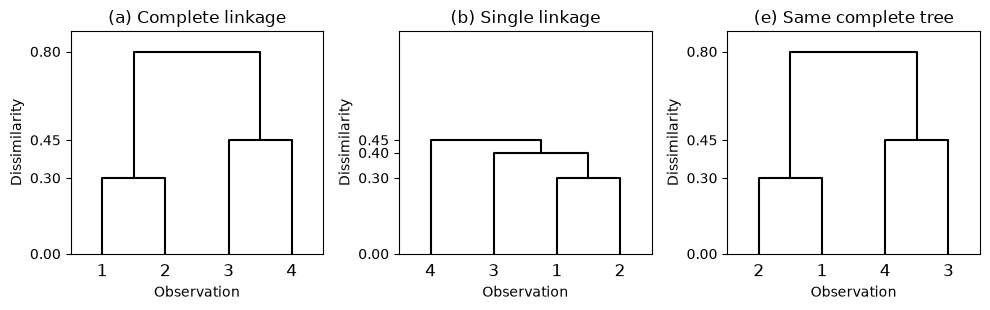

In [8]:
D = np.array([[0, .3, .4, .7], [.3, 0, .5, .8],
              [.4, .5, 0, .45], [.7, .8, .45, 0]])
complete = linkage(squareform(D), method='complete')
single = linkage(squareform(D), method='single')
swapped = complete.copy()
swapped[:2, :2] = swapped[:2, 1::-1]
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, tree, title in zip(axes, [complete, single, swapped],
                          ['(a) Complete linkage', '(b) Single linkage',
                           '(e) Same complete tree']):
    dendrogram(tree, labels=['1', '2', '3', '4'], ax=ax, color_threshold=0,
               above_threshold_color='black')
    ax.set(title=title, xlabel='Observation', ylabel='Dissimilarity')
    ax.set_yticks(sorted(set([0] + tree[:, 2].tolist())))
    ax.set_ylim(0, .88)
fig.tight_layout()
fig.savefig(RESULTS / 'islr_12_6_2.png', dpi=160, bbox_inches='tight')
plt.show()

### References
- Anuran Calls (MFCCs), UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/406/anuran+calls+mfccs
- Scikit-learn: [OneVsRestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.multiclass.OneVsRestClassifier.html), [LinearSVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html), [Jaccard score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.jaccard_score.html), and [Calinski-Harabasz score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.calinski_harabasz_score.html).
- James, Witten, Hastie, and Tibshirani, *An Introduction to Statistical Learning*, second edition, Section 12.6, Exercise 2, p. 548.